<a href="https://colab.research.google.com/github/ElafAhmedSaeed/-NodeMCU-Course-in-Arabic--NodeMCU/blob/main/Week_07_Zero_One_Few_Shot_Prompting_Colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Week 7 Zero Shot One Shot and Few Shot Prompting

Al-Nahrain University | College of Information Engineering  
Department of Automation & AI Engineering  
Asst. Lec. Elaf A. Saeed

Classify the same 12 engineering fault reports using 0, 1, and 4 examples.
Only the example block changes. There are **36 predictions**, not 36 training steps.
No model weights are updated. This is an in-context prompting experiment.

Complete Part 1 in LM Studio using the Laboratory Sheet. Use this notebook for
Part 2. Keep the results of the two environments separate.

Open this file in Google Colab. A GPU is useful; CPU inference is also supported.
Run the cells from top to bottom. Internet is needed to install packages and
download the public model. No paid API key is required.


## 1 Install the libraries

The Transformers version matches the Week 6 laboratory for continuity.
Colab provides PyTorch. If Colab requests a runtime restart, restart and run
the notebook from this cell again before importing the libraries.


In [ ]:
!pip -q install "transformers==4.56.0" safetensors matplotlib


ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio-client 2.7.2 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio 6.31.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
diffusers 0.42.1 requires huggingface-hub<3.0,>=1.32.0, but you have huggingface-hub 0.36.2 which is incompatible.


## 2 Fix the instructions and data

These are the same instructions, examples, and test reports as the sheet.
One-shot uses E1. Few-shot uses E1 to E4 in that order. Examples are separate
from the test set. Reference answers are introduced only after generation.


In [ ]:
from pathlib import Path
import csv
import json
import zipfile

LABELS = ['Electrical', 'Mechanical', 'Software', 'Communication']
INSTRUCTION = 'Classify the fault report into exactly one label.\nAllowed labels: Electrical, Mechanical, Software, Communication.\nElectrical: power supply, voltage, current, or electrical wiring faults.\nMechanical: faults in moving parts, bearings, belts, gears, or alignment.\nSoftware: errors in program code, internal calculations, or application logic.\nCommunication: failures in network links or data transmission between devices.\nUse the stated cause of the fault, not just its effect.\nReturn only the label. Do not add punctuation or an explanation.'
EXAMPLES = [
  {
    "id": "E1",
    "text": "A damaged power cable leaves the motor without supply voltage.",
    "label": "Electrical"
  },
  {
    "id": "E2",
    "text": "A worn drive belt slips on the conveyor pulley.",
    "label": "Mechanical"
  },
  {
    "id": "E3",
    "text": "A bug in the control program adds the same measurement twice.",
    "label": "Software"
  },
  {
    "id": "E4",
    "text": "A broken Ethernet link prevents the controller from sending data to the server.",
    "label": "Communication"
  }
]
TESTS = [
  {
    "id": "T01",
    "text": "The motor will not start because its power supply produces zero volts."
  },
  {
    "id": "T02",
    "text": "A worn pump bearing produces grinding noise when the shaft turns."
  },
  {
    "id": "T03",
    "text": "The monitoring app crashes because its code tries to divide a value by zero."
  },
  {
    "id": "T04",
    "text": "A loose network connector causes packets to be lost between the PLC and the display."
  },
  {
    "id": "T05",
    "text": "The dashboard shows stale readings because the wireless link to the sensor keeps disconnecting."
  },
  {
    "id": "T06",
    "text": "The conveyor stops because a short circuit trips the motor supply breaker."
  },
  {
    "id": "T07",
    "text": "The motor is powered, but a jammed gearbox prevents the conveyor from moving."
  },
  {
    "id": "T08",
    "text": "All readings arrive correctly, but an indexing bug in the app assigns them to the wrong machines."
  },
  {
    "id": "T09",
    "text": "The alert appears too early because the program uses the wrong comparison operator for the threshold."
  },
  {
    "id": "T10",
    "text": "The PLC and server work locally, but a failed network switch prevents messages from passing between them."
  },
  {
    "id": "T11",
    "text": "A loose terminal on the motor power circuit causes the supply voltage to drop intermittently."
  },
  {
    "id": "T12",
    "text": "The pump vibrates because the coupling between its motor and shaft is misaligned."
  }
]
STRATEGIES = [('Z', 'Zero-shot', 0), ('O', 'One-shot', 1), ('F', 'Few-shot', 4)]

def build_prompt(text, n):
    parts = [INSTRUCTION]
    if n:
        parts.append("Examples:")
        parts.extend(f"Fault: {e['text']}\nLabel: {e['label']}" for e in EXAMPLES[:n])
    parts.append(f"Fault: {text}\nLabel:")
    return "\n\n".join(parts)

OUT = Path("week07_results")
OUT.mkdir(exist_ok=True)
assert len(TESTS) == 12 and len(EXAMPLES) == 4
assert len({t["id"] for t in TESTS}) == 12
assert not ({t["text"] for t in TESTS} & {e["text"] for e in EXAMPLES})
print("Planned predictions:", len(STRATEGIES) * len(TESTS))
print("\nOne-shot prompt for T01:\n")
print(build_prompt(TESTS[0]["text"], 1))

blocks = []
for code, name, n in STRATEGIES:
    for test in TESTS:
        blocks.append(f"=== {code}-{test['id']} | {name} ===\n"
                      + build_prompt(test["text"], n))
(OUT / "prompts.txt").write_text("\n\n".join(blocks), encoding="utf-8")


Planned predictions: 36

One-shot prompt for T01:

Classify the fault report into exactly one label.
Allowed labels: Electrical, Mechanical, Software, Communication.
Electrical: power supply, voltage, current, or electrical wiring faults.
Mechanical: faults in moving parts, bearings, belts, gears, or alignment.
Software: errors in program code, internal calculations, or application logic.
Communication: failures in network links or data transmission between devices.
Use the stated cause of the fault, not just its effect.
Return only the label. Do not add punctuation or an explanation.

Examples:

Fault: A damaged power cable leaves the motor without supply voltage.
Label: Electrical

Fault: The motor will not start because its power supply produces zero volts.
Label:


29680

## 3 Load one model and record the environment

Use Qwen2.5-0.5B-Instruct for all three strategies. CUDA uses float16;
CPU uses float32 for compatibility. These types store the same model's weights
at different numerical precision. The model is downloaded or reused from cache.


In [ ]:
import torch
import transformers
import matplotlib.pyplot as plt
from IPython.display import display
from transformers import AutoModelForCausalLM, AutoTokenizer, GenerationConfig, set_seed

MODEL_ID = "Qwen/Qwen2.5-0.5B-Instruct"
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
DTYPE = torch.float16 if DEVICE == "cuda" else torch.float32
SEED = 42
MAX_NEW_TOKENS = 16
set_seed(SEED)

model = AutoModelForCausalLM.from_pretrained(
    MODEL_ID, dtype=DTYPE, use_safetensors=True
).to(DEVICE).eval()
revision = getattr(model.config, "_commit_hash", None)
tokenizer = AutoTokenizer.from_pretrained(MODEL_ID, revision=revision)
eos_id = model.generation_config.eos_token_id
pad_id = tokenizer.pad_token_id
if pad_id is None:
    pad_id = eos_id[0] if isinstance(eos_id, list) else eos_id

cfg = GenerationConfig(
    do_sample=False, num_beams=1, max_new_tokens=MAX_NEW_TOKENS,
    eos_token_id=eos_id, pad_token_id=pad_id,
)
metadata = {
    "model_id": MODEL_ID, "model_revision": revision,
    "transformers": transformers.__version__, "torch": str(torch.__version__),
    "device": DEVICE, "dtype": str(DTYPE),
    "hardware": torch.cuda.get_device_name(0) if DEVICE == "cuda" else "CPU",
    "seed": SEED, "seed_note": "Recorded for continuity; greedy token selection does not sample.",
    "generation_config": cfg.to_dict(), "instruction": INSTRUCTION,
    "examples": EXAMPLES, "test_set": TESTS,
    "strategies": [{"code": c, "name": s, "examples": n} for c, s, n in STRATEGIES],
    "planned_predictions": 36,
    "scoring_rule": "Case and whitespace normalization only; a single allowed label is required.",
}
(OUT / "metadata.json").write_text(json.dumps(metadata, indent=2), encoding="utf-8")
print(json.dumps({k: metadata[k] for k in
                 ["model_id", "model_revision", "device", "hardware", "dtype"]}, indent=2))


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


config.json:   0%|          | 0.00/659 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/988M [00:00<?, ?B/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

{
  "model_id": "Qwen/Qwen2.5-0.5B-Instruct",
  "model_revision": "7ae557604adf67be50417f59c2c2f167def9a775",
  "device": "cuda",
  "hardware": "Tesla T4",
  "dtype": "torch.float16"
}


## 4 Generate and save all predictions

Each call contains one user message with the instructions, optional examples,
and one test report. There is no previous chat history and no reference answer
in the test query. Greedy decoding is fixed for all strategies; temperature,
Top-P and Top-K are not varied in this laboratory.

This cell overwrites `raw_predictions.jsonl` when rerun. If a call fails, fix the
runtime problem and rerun this cell to complete the same full set of 36 calls.
Do not change examples after looking at the test answers or choose only favorable outputs.


In [ ]:
def classify_one(code, name, n, test):
    prompt = build_prompt(test["text"], n)
    encoded = tokenizer.apply_chat_template(
        [{"role": "user", "content": prompt}],
        add_generation_prompt=True, tokenize=True,
        return_dict=True, return_tensors="pt",
    ).to(DEVICE)
    input_length = encoded["input_ids"].shape[1]
    with torch.inference_mode():
        output = model.generate(**encoded, generation_config=cfg)
    new_ids = output[0, input_length:].tolist()
    response = tokenizer.decode(
        new_ids, skip_special_tokens=True, clean_up_tokenization_spaces=False
    )
    return {
        "run_id": f"{code}-{test['id']}", "strategy_code": code,
        "strategy": name, "example_count": n, "test_id": test["id"],
        "fault": test["text"], "prompt": prompt, "raw_response": response,
        "input_tokens": input_length, "new_tokens": len(new_ids),
        "cap_reached": len(new_ids) >= MAX_NEW_TOKENS,
    }

records = []
with (OUT / "raw_predictions.jsonl").open("w", encoding="utf-8") as stream:
    for code, name, n in STRATEGIES:
        for test in TESTS:
            result = classify_one(code, name, n, test)
            records.append(result)
            stream.write(json.dumps(result, ensure_ascii=False) + "\n")
            stream.flush()
            print(f"{result['run_id']}: {result['raw_response']!r}")
assert len(records) == 36


Z-T01: 'Electrical'
Z-T02: 'Mechanical'
Z-T03: 'Software'
Z-T04: 'Software'
Z-T05: 'Software'
Z-T06: 'Electrical'
Z-T07: 'Electrical'
Z-T08: 'Software'
Z-T09: 'Software'
Z-T10: 'Communication'
Z-T11: 'Electrical'
Z-T12: 'Mechanical'
O-T01: 'Electrical'
O-T02: 'Electrical'
O-T03: 'Software'
O-T04: 'Electrical'
O-T05: 'Electrical'
O-T06: 'Electrical'
O-T07: 'Electrical'
O-T08: 'Electrical'
O-T09: 'Electrical'
O-T10: 'Electrical'
O-T11: 'Electrical'
O-T12: 'Electrical'
F-T01: 'Electrical'
F-T02: 'Electrical'
F-T03: 'Software'
F-T04: 'Electrical'
F-T05: 'Software'
F-T06: 'Electrical'
F-T07: 'Electrical'
F-T08: 'Software'
F-T09: 'Software'
F-T10: 'Communication'
F-T11: 'Electrical'
F-T12: 'Electrical'


## 5 Reveal the reference answers and score

Keep the predictions unchanged. A correct label earns 1 point; an incorrect,
empty, or invalid response earns 0. Ignore letter case and extra whitespace.
Do not remove punctuation or extract a label from an explanation.
`Communication.` and `The fault is Electrical` are invalid under this strict rule.

Accuracy = correct predictions / 12 × 100. Invalid predictions stay in the
denominator. If any call did not run, complete it before calculating the table.


In [ ]:
GOLD = {'T01': 'Electrical', 'T02': 'Mechanical', 'T03': 'Software', 'T04': 'Communication', 'T05': 'Communication', 'T06': 'Electrical', 'T07': 'Mechanical', 'T08': 'Software', 'T09': 'Software', 'T10': 'Communication', 'T11': 'Electrical', 'T12': 'Mechanical'}

def normalize_label(response):
    lookup = {label.casefold(): label for label in LABELS}
    return lookup.get(" ".join(response.split()).casefold(), "INVALID")

def score_records(records):
    expected = {(code, test["id"]) for code, _, _ in STRATEGIES for test in TESTS}
    observed = [(r["strategy_code"], r["test_id"]) for r in records]
    assert len(observed) == 36 and set(observed) == expected, "Complete all 36 unique calls first."
    scored = []
    for r in records:
        prediction = normalize_label(r["raw_response"])
        scored.append({**r, "prediction": prediction,
                       "gold_label": GOLD[r["test_id"]],
                       "invalid": int(prediction == "INVALID"),
                       "correct": int(prediction == GOLD[r["test_id"]])})
    summary = []
    for code, name, n in STRATEGIES:
        rows = [r for r in scored if r["strategy_code"] == code]
        correct = sum(r["correct"] for r in rows)
        summary.append({"strategy": name, "example_count": n, "test_count": len(rows),
                        "correct": correct, "incorrect": len(rows) - correct,
                        "invalid": sum(r["invalid"] for r in rows),
                        "accuracy_percent": round(100 * correct / len(rows), 2)})
    return scored, summary

assert set(GOLD) == {t["id"] for t in TESTS}
scored, summary = score_records(records)
for row in summary:
    print(f"{row['strategy']}: {row['correct']}/12 = {row['accuracy_percent']:.2f}%"
          f"; invalid = {row['invalid']}")


Zero-shot: 9/12 = 75.00%; invalid = 0
One-shot: 4/12 = 33.33%; invalid = 0
Few-shot: 7/12 = 58.33%; invalid = 0


## 6 Export the tables and draw the chart

`predictions.csv` contains all 36 raw outputs, predicted labels, reference
labels, and scores. `accuracy_summary.csv` contains the three strategy totals.
`test_key.csv` contains the 12 reference answers. CSV files can be opened in Excel.
The chart shows this Colab run only. Do not mix it with the LM Studio results.


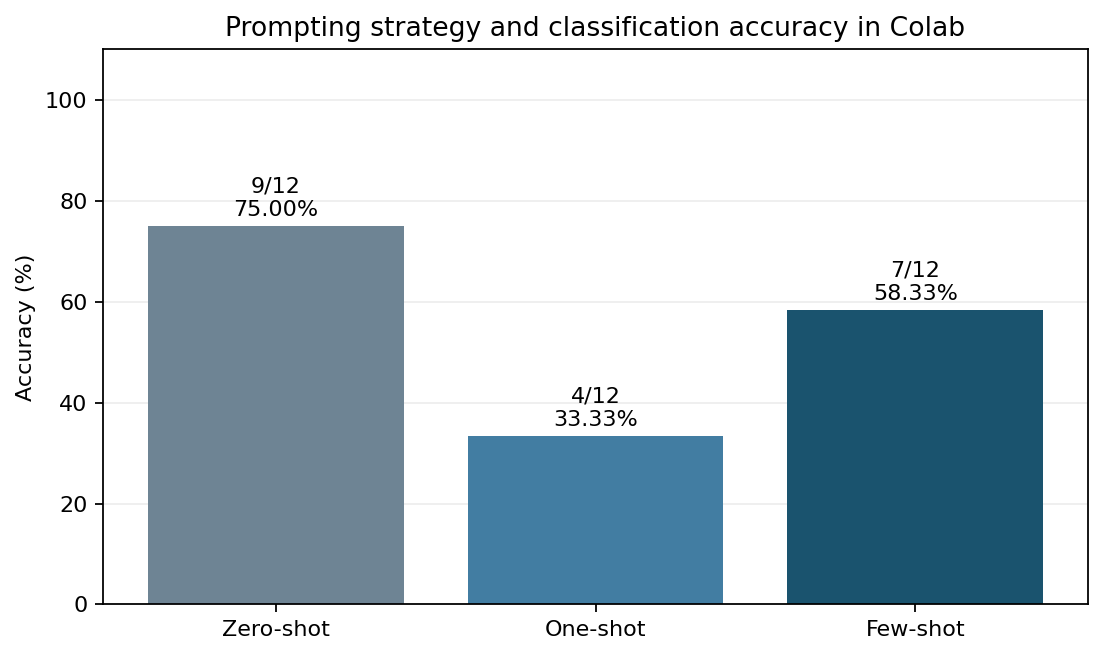

In [ ]:
def write_csv(path, rows, fields):
    with path.open("w", encoding="utf-8-sig", newline="") as stream:
        writer = csv.DictWriter(stream, fieldnames=fields, extrasaction="ignore")
        writer.writeheader()
        writer.writerows(rows)

write_csv(OUT / "predictions.csv", scored, [
    "run_id", "strategy", "example_count", "test_id", "fault", "raw_response",
    "prediction", "gold_label", "correct", "invalid", "input_tokens", "new_tokens", "cap_reached",
])
write_csv(OUT / "accuracy_summary.csv", summary, list(summary[0]))
key_rows = [{"test_id": t["id"], "fault": t["text"], "gold_label": GOLD[t["id"]]} for t in TESTS]
write_csv(OUT / "test_key.csv", key_rows, ["test_id", "fault", "gold_label"])

fig, ax = plt.subplots(figsize=(7, 4.2), dpi=160)
bars = ax.bar([r["strategy"] for r in summary],
              [r["accuracy_percent"] for r in summary], color=["#6E8494", "#427DA2", "#1A536E"])
ax.set_ylim(0, 110)
ax.set_yticks([0, 20, 40, 60, 80, 100])
ax.set_ylabel("Accuracy (%)")
ax.set_title("Prompting strategy and classification accuracy in Colab")
ax.yaxis.grid(True, alpha=0.22)
ax.set_axisbelow(True)
for bar, row in zip(bars, summary):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 2,
            f"{row['correct']}/12\n{row['accuracy_percent']:.2f}%", ha="center", fontsize=10)
fig.tight_layout()
fig.savefig(OUT / "accuracy_comparison.png", bbox_inches="tight")
plt.show()


## 7 Inspect errors before writing the discussion

Read the full report and raw output for each error. Distinguish an incorrect
category from an invalid response format. Keep every error in the main score.
If all predictions are correct, report the tie and the small test set as a
limitation. Do not claim that few-shot is always best.


In [ ]:
errors = [r for r in scored if not r["correct"]]
if not errors:
    print("No errors in this Colab run. All three strategies scored 12/12.")
for r in errors:
    print(f"\n{r['run_id']} | Reference: {r['gold_label']} | Predicted: {r['prediction']}")
    print("Fault:", r["fault"])
    print("Raw output:", repr(r["raw_response"]))



Z-T04 | Reference: Communication | Predicted: Software
Fault: A loose network connector causes packets to be lost between the PLC and the display.
Raw output: 'Software'

Z-T05 | Reference: Communication | Predicted: Software
Fault: The dashboard shows stale readings because the wireless link to the sensor keeps disconnecting.
Raw output: 'Software'

Z-T07 | Reference: Mechanical | Predicted: Electrical
Fault: The motor is powered, but a jammed gearbox prevents the conveyor from moving.
Raw output: 'Electrical'

O-T02 | Reference: Mechanical | Predicted: Electrical
Fault: A worn pump bearing produces grinding noise when the shaft turns.
Raw output: 'Electrical'

O-T04 | Reference: Communication | Predicted: Electrical
Fault: A loose network connector causes packets to be lost between the PLC and the display.
Raw output: 'Electrical'

O-T05 | Reference: Communication | Predicted: Electrical
Fault: The dashboard shows stale readings because the wireless link to the sensor keeps disconne

## 8 Download the experiment files

The ZIP includes metadata, all 36 prompts, raw outputs, scored predictions,
the answer key, the three-row summary, and the Colab chart. Download it before
closing Colab. Complete the discussion and keep LM Studio evidence separately.


In [ ]:
export_names = ["metadata.json", "prompts.txt", "raw_predictions.jsonl", "predictions.csv",
                "test_key.csv", "accuracy_summary.csv", "accuracy_comparison.png"]
archive = Path("Week_07_Experiment_Results.zip")
with zipfile.ZipFile(archive, "w", compression=zipfile.ZIP_DEFLATED) as bundle:
    for name in export_names:
        path = OUT / name
        assert path.exists(), f"Missing export: {path}. Run the previous cells first."
        bundle.write(path, arcname=name)
print("Created:", archive.resolve())
try:
    from google.colab import files
except ImportError:
    print("Outside Colab: download the ZIP from your notebook file browser.")
else:
    files.download(str(archive))


Created: /content/Week_07_Experiment_Results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Discussion

1. Which strategy had the highest accuracy in each environment? Report counts and percentages.
2. Quote one raw output that changed from incorrect to correct, or explain that no such case occurred.
3. Did the one electrical example appear to favor Electrical? Use a test ID as evidence; one observation is not proof.
4. Why might four examples help, fail to help, or reduce accuracy? Discuss coverage, wording, format, and task difficulty.
5. Why must the same test set and settings be used, with new chats and no test answers in the prompts?
6. Recommend one strategy for this task. State one limitation and propose a new test set for future work.

## References

- [Language Models are Few-Shot Learners](https://arxiv.org/abs/2005.14165)
- [Qwen2.5-0.5B-Instruct](https://huggingface.co/Qwen/Qwen2.5-0.5B-Instruct)
- [Transformers 4.56 generation configuration](https://huggingface.co/docs/transformers/v4.56.0/main_classes/text_generation)
